# Project Phase 2

### Abigail Biggs, Ishita Kushwaha, Alison Markus

## Project Overview

### Central Motivation

Clinical trials are the bridge between a laboratory finding and an approved treatment, but they are costly and slow, and many never finish. Prior work shows that more than a quarter of randomized trials are stopped early, most often because too few patients are recruited [1][3][4]. A trial that ends early wastes funding and effort and leaves its research question unanswered. Much of the existing literature studies a single disease area, such as cardiovascular trials. This project uses registry data on **cancer trials** to test whether basic, easily observed trial characteristics carry predictive signal about how a trial turns out.

### Key Questions
 
1. **Enrollment (regression):** Can a trial's phase, sponsor class, number of study sites, and duration predict its enrollment size?
2. **Termination (classification):** Can a trial's phase, sponsor class, study type, enrollment, and number of sites predict whether it ends as Completed or Terminated? Duration is excluded here because, for terminated trials, it reflects when the trial stopped and would leak the outcome.
 
### Data Processing Pipeline
 
1. **Acquisition.** Records are pulled in Python with `requests` from the ClinicalTrials.gov API v2 (`/api/v2/studies`). The query filters on `overallStatus` in {COMPLETED, TERMINATED} and `query.cond = "cancer"`, with `pageSize = 200`. The loop follows `nextPageToken` until 600 studies are collected.
2. **Parsing.** Each study's nested JSON (`protocolSection`) is flattened into one row per trial. Extracted fields: NCT ID, overall status, start and completion dates, phase(s), study type, enrollment count, lead sponsor class, and number of listed study locations (`n_sites`, the length of the locations list).
3. **Cleaning.**
   - Multi-phase trials are joined into one string (e.g., `PHASE1, PHASE2`). Trials with no phase (empty string or `NA`, mostly observational and non-drug studies) are relabeled `NOT_APPLICABLE` so they are not read back as missing values from the CSV.
   - Start and completion dates are parsed with `format="ISO8601"`, since the API mixes `YYYY-MM` and `YYYY-MM-DD`. Month-only dates resolve to the first of the month, so durations are accurate to roughly one month. Unparseable values become `NaT`.
   - `duration_days` is computed as completion date minus start date.
4. **Resulting dataset.** 600 rows (511 Completed, 89 Terminated). Numeric features: `enrollment`, `n_sites`, `duration_days`. Categorical features: `phase`, `sponsor_class`, `study_type`, `status`. Missing values: 23 in `enrollment`, 31 in `end` and `duration_days`, 2 in `start`. The cleaned table is saved to `clinical_trials.csv` so the API does not need to be re-queried.
5. **Planned preparation for modeling.** Drop rows with missing values in the variables each question uses, one-hot encode the categorical features, and split into train and test sets (stratified by `status` for Q2). Because only about 15% of trials are terminated, Q2 will be evaluated with precision and recall in addition to accuracy.
 
### References
 
[1] https://pmc.ncbi.nlm.nih.gov/articles/PMC6937940
[3] https://scholars.duke.edu/publication/1033788
[4] https://bmjopen.bmj.com/content/7/6/e013482

### Data Cleaning

In [1]:
import requests
import pandas as pd

# --- 1. Collect data from the ClinicalTrials.gov API v2 ---
BASE = "https://clinicaltrials.gov/api/v2/studies"
params = {
    "filter.overallStatus": "COMPLETED|TERMINATED",
    "query.cond": "cancer",
    "pageSize": 200,
    "format": "json",
}

studies, token = [], None
while len(studies) < 600:
    if token:
        params["pageToken"] = token
    r = requests.get(BASE, params=params)
    r.raise_for_status()
    data = r.json()
    studies.extend(data["studies"])
    token = data.get("nextPageToken")
    if not token:
        break

# --- 2. Pull out the fields ---
rows = []
for s in studies:
    p = s["protocolSection"]
    rows.append({
        "nct_id": p["identificationModule"]["nctId"],
        "status": p["statusModule"]["overallStatus"],
        "start": p["statusModule"].get("startDateStruct", {}).get("date"),
        "end": p["statusModule"].get("completionDateStruct", {}).get("date"),
        "phase": ", ".join(p.get("designModule", {}).get("phases", [])),
        "study_type": p.get("designModule", {}).get("studyType"),
        "enrollment": p.get("designModule", {}).get("enrollmentInfo", {}).get("count"),
        "sponsor_class": p.get("sponsorCollaboratorsModule", {}).get("leadSponsor", {}).get("class"),
        "n_sites": len(p.get("contactsLocationsModule", {}).get("locations", [])),
    })

df = pd.DataFrame(rows)

# --- 3. Clean: label unphased trials so they survive the CSV round trip ---
df["phase"] = df["phase"].replace({"": "NOT_APPLICABLE", "NA": "NOT_APPLICABLE"})

# --- 4. Parse dates (handles both "2019-03" and "2019-03-15") ---
df["start"] = pd.to_datetime(df["start"], format="ISO8601", errors="coerce")
df["end"] = pd.to_datetime(df["end"], format="ISO8601", errors="coerce")
df["duration_days"] = (df["end"] - df["start"]).dt.days

# --- 5. Save ---
df.to_csv("clinical_trials.csv", index=False)
print("Saved clinical_trials.csv with shape", df.shape)

# --- 6. Quick check ---
print("\nMissing values:")
print(df.isna().sum())
print("\nStatus counts:")
print(df["status"].value_counts())
print("\nPhase counts:")
print(df["phase"].value_counts())

df.head()

Saved clinical_trials.csv with shape (600, 10)

Missing values:
nct_id            0
status            0
start             4
end              29
phase             0
study_type        0
enrollment       11
sponsor_class     0
n_sites           0
duration_days    30
dtype: int64

Status counts:
status
COMPLETED     498
TERMINATED    102
Name: count, dtype: int64

Phase counts:
phase
NOT_APPLICABLE    239
PHASE2            161
PHASE1             96
PHASE3             49
PHASE1, PHASE2     30
EARLY_PHASE1       10
PHASE4             10
PHASE2, PHASE3      5
Name: count, dtype: int64


,nct_id,status,start,end,phase,study_type,enrollment,sponsor_class,n_sites,duration_days
0,NCT01191060,COMPLETED,2010-10-01,2018-11-30,PHASE3,INTERVENTIONAL,700.0,OTHER,68,2982.0
1,NCT02204982,TERMINATED,2014-09-01,2017-03-01,PHASE3,INTERVENTIONAL,13.0,INDUSTRY,5,912.0
2,NCT03281382,COMPLETED,2017-07-01,2019-05-28,PHASE1,INTERVENTIONAL,12.0,OTHER,1,696.0
3,NCT00193882,COMPLETED,2003-07-07,2013-06-18,PHASE3,INTERVENTIONAL,220.0,OTHER,25,3634.0
4,NCT02559323,COMPLETED,2010-05-01,2016-07-01,NOT_APPLICABLE,OBSERVATIONAL,2000.0,OTHER,1,2253.0


### Two visualizations to answer our key questions

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("clinical_trials.csv", keep_default_na=False, na_values=[""])
df["terminated"] = (df["status"] == "TERMINATED").astype(int)

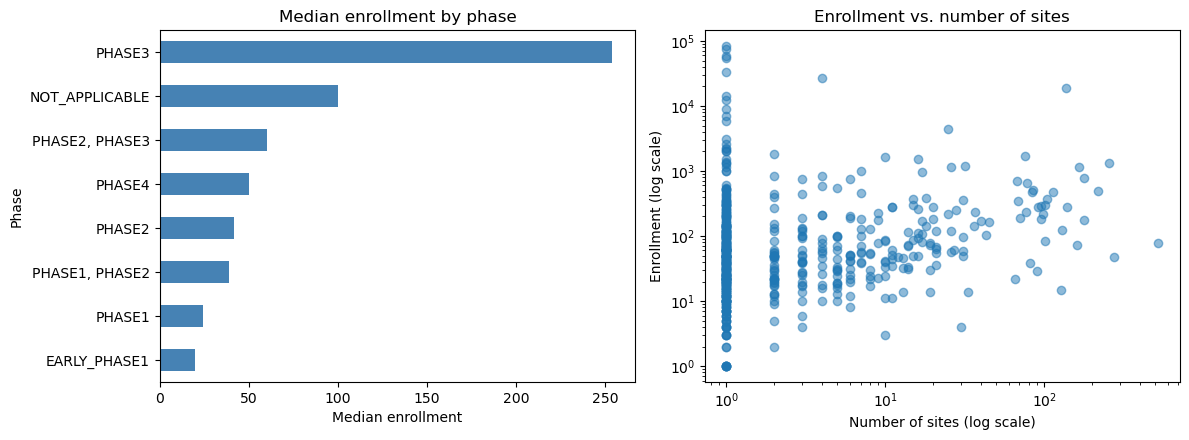

In [3]:
# Figure 1: Can a trial's phase, sponsor class, number of study sites, and duration predict its enrollment size?
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) median enrollment by phase
df.groupby("phase")["enrollment"].median().sort_values().plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set_xlabel("Median enrollment")
ax[0].set_ylabel("Phase")
ax[0].set_title("Median enrollment by phase")

# (b) enrollment vs. number of sites
ax[1].scatter(df["n_sites"], df["enrollment"], alpha=0.5)
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel("Number of sites (log scale)")
ax[1].set_ylabel("Enrollment (log scale)")
ax[1].set_title("Enrollment vs. number of sites")

plt.tight_layout()
plt.show()

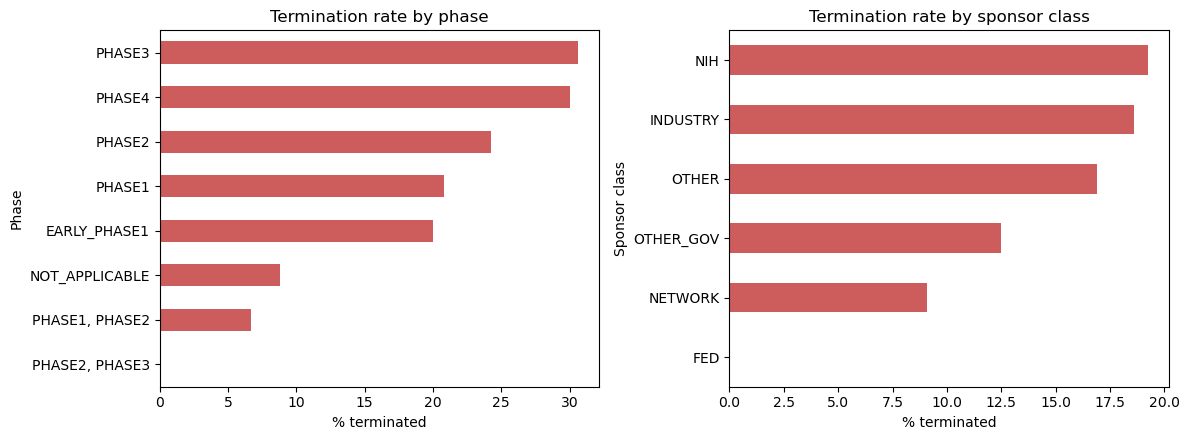

In [4]:
# Figure 2: Can a trial's phase, sponsor class, study type, enrollment, and number of sites predict whether it ends as Completed or Terminated?
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# (a) % terminated by phase
(df.groupby("phase")["terminated"].mean() * 100).sort_values().plot(kind="barh", ax=ax[0], color="indianred")
ax[0].set_xlabel("% terminated")
ax[0].set_ylabel("Phase")
ax[0].set_title("Termination rate by phase")

# (b) % terminated by sponsor class
(df.groupby("sponsor_class")["terminated"].mean() * 100).sort_values().plot(kind="barh", ax=ax[1], color="indianred")
ax[1].set_xlabel("% terminated")
ax[1].set_ylabel("Sponsor class")
ax[1].set_title("Termination rate by sponsor class")

plt.tight_layout()
plt.show()

### Two Functions for Evaluating ML Model
For our first question, we will use the mean absolute error (MAE) to see how close the predicted enrollment numbers are to the actual enrollment numbers. In this instance, smaller error means the model's predictions are more accurate.

For our second question, we will use recall (recall_termination) to see how many trials that actually terminated were correctly predicted as terminated. This is useful because our dataset has more completed trials than terminated trials, so we want to make sure the model can identify terminated trials.

In [5]:
import numpy as np

# MAE Calculations
def MAE(actual, predicted):
    difference = np.abs(np.array(actual) - np.array(predicted))
    return np.mean(difference)

In [6]:
# Recall calculation
def recall_termination(actual, predicted):
    total_terminated = 0
    correct_terminated = 0
    for i in range(len(actual)):
        if actual[i] == 1:
            total_terminated += 1
            if predicted[i] == 1:
                correct_terminated += 1
    if total_terminated == 0:
        return None
        
    return round(correct_terminated / total_terminated, 2)

In [7]:
# Test function 1 (MAE)
actual_enroll = [100, 200, 300, 400]
predicted_enroll = [120, 210, 270, 400]

print("The Mean Absolute Error:", MAE(actual_enroll, predicted_enroll))

# Test function 2 (recall_termination)
actual_status = [0, 1, 0, 1, 1]
predicted_status = [0, 1, 1, 0, 1]

print("The Termination Recall:", recall_termination(actual_status, predicted_status))

The Mean Absolute Error: 15.0
The Termination Recall: 0.67


### Potential Ethical Implications
1. A concern we have is that some clinical trial records have missing information, which could make our predictions less accurate. Also, some trials that have smaller studies, or those focusing on rare cancers, may have fewer participants. However, that doesn't necessarily mean they are less successful or important, it's just something to keep in mind during evaluation.

2. Another concern is how the predictions could be used. If a model predicts that a clinical trial is likely to be terminated, it could potentially decrease funding for a study that might still be important. Trials can also be terminated for different reasons, so our model may not tell the full story. So, we would want to make sure the predictions are used to help researchers make decisions rather than being the only factor in determining whether a trial should occur or not.